# Predicting NSE Closing Prices with Regression, and a Look-Ahead Bias Check

**Original project (IIT Kharagpur term project, 2021; supervisor Dr. Debjani Chakraborty).** For 30 NSE stocks, a multiple regression on *previous close, day low and number of trades* predicted the closing price within a 95% band far more often than a simple regression on previous close alone.

**This rebuild asks a validation question.** The day's low and number of trades are only known **after** the market closes, so the original multiple regression uses information a forecaster wouldn't have yet. This is called *look-ahead bias*. This notebook:
1. replicates the original comparison
2. rebuilds the model using only information available in time
3. tests every model against a **random walk** ("today's close = yesterday's close")

Training data: 17 Mar 2020 – 16 Mar 2021. Test data: 17 Mar 2021 – 18 Apr 2021 (the same windows as the original project).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
warnings.filterwarnings("ignore")
import data as D
import models as M

FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data
Daily data from NSE's *Security-wise Price volume & Deliverable position* report, the same source as the original project: prices, volume, turnover, number of trades and deliverable quantity.

In [2]:
prices = D.load_prices()
train, test = D.split(prices)
log_path = ROOT / "data" / "raw" / "download_log.json"
if log_path.exists():
    log = json.loads(log_path.read_text())
    missing = [c for c, v in log.items() if not v["symbol"]]
    print("Not available from NSE:", missing or "none")
coverage = (prices.groupby(["symbol", "company"])
            .apply(lambda d: pd.Series({"train_days": ((d.date >= D.TRAIN_START) & (d.date <= D.TRAIN_END)).sum(),
                                        "test_days": ((d.date >= D.TEST_START) & (d.date <= D.TEST_END)).sum()}))
            .reset_index())
print(f"{coverage.symbol.nunique()} stocks, {len(train):,} training rows, {len(test):,} test rows")
coverage.sort_values("train_days").head(8)

29 stocks, 7,056 training rows, 580 test rows


,symbol,company,train_days,test_days
2,BECTORFOOD,Mrs Bectors Food,56,20
0,APOLLOHOSP,Apollo Hospitals,250,20
1,BANDHANBNK,Bandhan Bank,250,20
3,BHARTIARTL,Bharti Airtel,250,20
4,COALINDIA,Coal India,250,20
5,DLF,DLF,250,20
6,DMART,DMart,250,20
7,FEDERALBNK,Federal Bank,250,20


## 2. Choosing variables: multicollinearity
The original report started with 11 candidate variables and dropped the highly collinear ones. The **variance inflation factor (VIF)** measures how well each variable can be predicted from the others. A VIF above about 10 means severe overlap, which makes the coefficients unstable.

In [3]:
vif_all = pd.concat({s: M.vif_table(d, D.CANDIDATES) for s, d in train.groupby("symbol") if len(d) > 60}, axis=1)
vif_summary = pd.DataFrame({"median VIF across stocks": vif_all.median(axis=1)}).sort_values("median VIF across stocks", ascending=False)
vif_chosen = pd.concat({s: M.vif_table(d, ["prev_close", "low", "trades"]) for s, d in train.groupby("symbol") if len(d) > 60}, axis=1)
print("Median VIF of the 3 variables the original project kept:")
print(vif_chosen.median(axis=1).round(1).to_string())
vif_summary

Median VIF of the 3 variables the original project kept:
prev_close   82.100
low          83.100
trades        1.100


,median VIF across stocks
vwap,"2,778.223"
high,"1,134.922"
low,973.907
last,464.947
open,441.104
prev_close,280.977
volume,69.000
turnover,49.976
deliverable_qty,16.636
trades,7.607


The six price variables (open, high, low, last, VWAP, previous close) are almost copies of each other, with very large VIFs. Even the reduced set of previous close + low still has a large VIF, because yesterday's close and today's low move closely together.

## 3. Replicating the original comparison, then fixing it
Every model is fitted **separately for each stock** on its training year, then gives a forecast and a 95% prediction interval for each test day.
- **Coverage** is the share of test days where the actual close falls inside the 95% interval. A well-calibrated model should be close to 95%.
- A stock counts as **well predicted** if coverage is at least 90%. This is how this notebook applies the original "within the 95% band" criterion.
- **DM p-value** comes from the Diebold–Mariano test of whether a model's errors are significantly smaller than the random walk's.

In [4]:
scores, forecasts = M.run_all(train, test)
summary = M.summarise(scores)
(ROOT / "results").mkdir(exist_ok=True)
summary.to_csv(ROOT / "results" / "summary.csv")
scores.to_csv(ROOT / "results" / "per_stock_scores.csv", index=False)
summary

,stocks,median_MAPE_%,mean_coverage_%,stocks_with_coverage_>=90%,median_interval_width_%,stocks_beating_RW,stocks_sig_better_than_RW,uses_future_info
model,,,,,,,,
Random walk,28,1.975,89.107,19,8.183,NaN,NaN,False
Simple (original),28,1.955,89.464,19,8.286,19.000,3.000,False
Same-day (original),28,0.984,92.321,22,4.597,28.000,14.000,True
Lagged (fixed),28,2.003,90.000,19,8.245,13.000,0.000,False
At-open (fixed),28,1.749,90.714,20,7.492,26.000,4.000,False


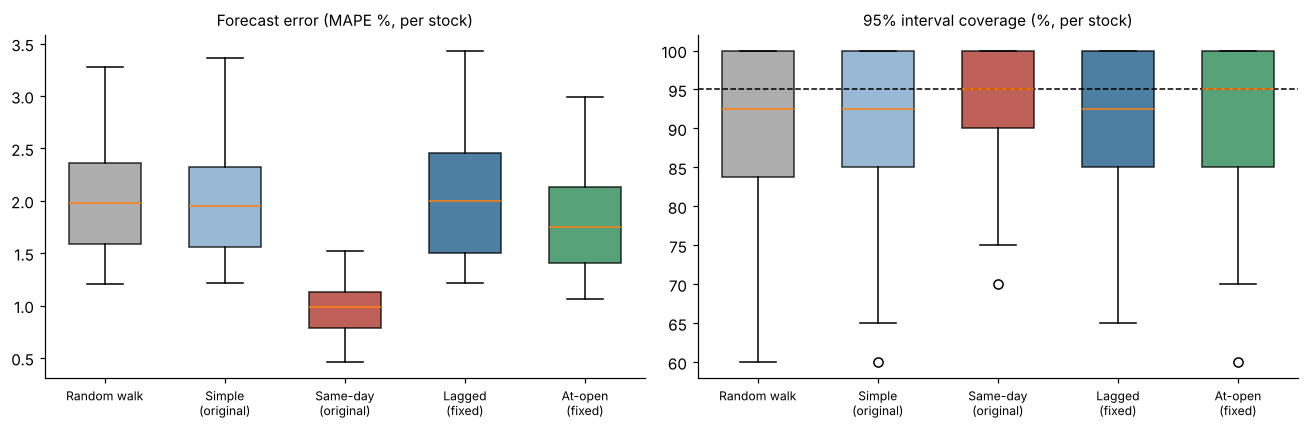

In [5]:
order = ["Random walk", "Simple (original)", "Same-day (original)", "Lagged (fixed)", "At-open (fixed)"]
colors = {"Random walk": "#999999", "Simple (original)": "#7fa7c9", "Same-day (original)": "#b03a2e",
          "Lagged (fixed)": "#1f5f8b", "At-open (fixed)": "#2e8b57"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in [(axes[0], "MAPE_%", "Forecast error (MAPE %, per stock)"),
                          (axes[1], "coverage_%", "95% interval coverage (%, per stock)")]:
    data = [scores.loc[scores.model == m, metric].values for m in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6)
    for patch, m in zip(bp["boxes"], order):
        patch.set_facecolor(colors[m]); patch.set_alpha(0.8)
    ax.set_xticks(range(1, len(order) + 1), [o.replace(" (", "\n(") for o in order], fontsize=8)
    ax.set_title(title, fontsize=10)
axes[1].axhline(95, color="black", ls="--", lw=1)
fig.tight_layout(); fig.savefig(FIG / "model_comparison.png", bbox_inches="tight"); plt.show()

## 4. Where the fixed model misses
Per-stock results for the look-ahead-free model, sorted from worst coverage to best. The original report traced its one miss to IDFC First Bank's qualified institutional placement (QIP) share sale in March 2021. Stock-specific events like that can't be predicted from past prices.

In [6]:
lagged = scores[scores.model == "Lagged (fixed)"].set_index("symbol")
lagged[["MAPE_%", "coverage_%", "interval_width_%", "DM_p_vs_RW", "beats_RW"]].sort_values("coverage_%").head(10)

,MAPE_%,coverage_%,interval_width_%,DM_p_vs_RW,beats_RW
symbol,,,,,
JSWSTEEL,2.578,65.000,6.293,0.881,True
IDFCFIRSTB,3.435,70.000,7.649,0.073,False
TATASTEEL,2.773,70.000,6.438,0.942,True
DLF,2.674,80.000,8.628,0.154,False
TATAMOTORS,2.506,80.000,8.185,0.103,False
IRCTC,2.208,80.000,8.338,0.251,False
SBIN,1.935,85.000,7.570,0.349,False
OIL,1.968,85.000,8.292,0.135,True
WIPRO,2.041,85.000,6.405,0.600,True


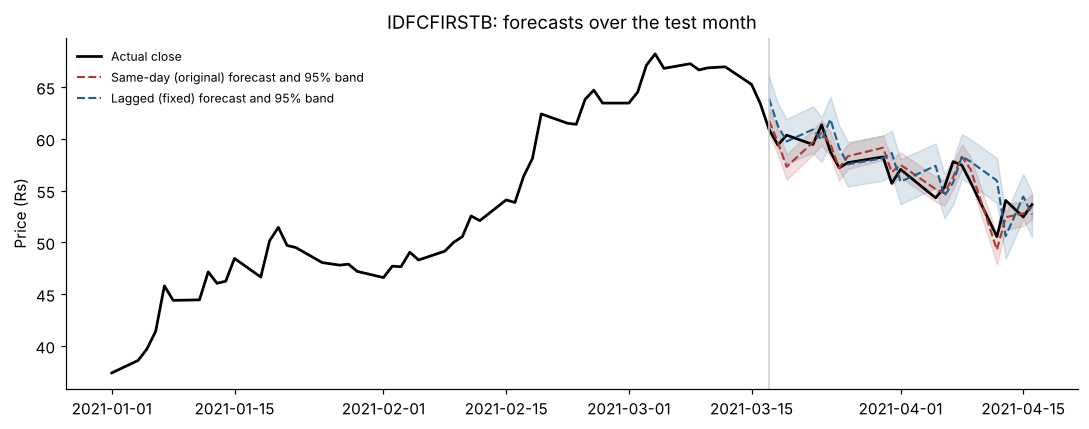

In [7]:
sym = "IDFCFIRSTB" if ("IDFCFIRSTB", "Lagged (fixed)") in forecasts else lagged["coverage_%"].idxmin()
fig, ax = plt.subplots(figsize=(10, 4))
hist = prices[(prices.symbol == sym) & (prices.date >= "2021-01-01") & (prices.date <= D.TEST_END)]
ax.plot(hist.date, hist.close, color="black", lw=1.8, label="Actual close")
for name, c in [("Same-day (original)", "#b03a2e"), ("Lagged (fixed)", "#1f5f8b")]:
    fc = forecasts[(sym, name)]
    ax.fill_between(fc.date, fc.lower, fc.upper, color=c, alpha=0.15)
    ax.plot(fc.date, fc.forecast, color=c, lw=1.4, ls="--", label=f"{name} forecast and 95% band")
ax.axvline(pd.Timestamp(D.TEST_START), color="#cccccc", lw=1)
ax.set_title(f"{sym}: forecasts over the test month"); ax.set_ylabel("Price (Rs)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "example_stock.png", bbox_inches="tight"); plt.show()

## 5. Placebo test: is the same-day model's edge real?
Here's a simple way to settle it. Simulate 30 fake stocks whose prices are **pure random walks**, where nothing can be predicted, and run exactly the same models. Any model that "beats" the random walk on this data must be using information it shouldn't have.

In [8]:
fake = M.simulate_placebo(n_stocks=30, seed=0)
fake_train, fake_test = D.split(fake)
fake_scores, _ = M.run_all(fake_train, fake_test)
placebo = M.summarise(fake_scores)
placebo.to_csv(ROOT / "results" / "placebo_summary.csv")
placebo[["median_MAPE_%", "mean_coverage_%", "stocks_beating_RW", "stocks_sig_better_than_RW", "uses_future_info"]]

,median_MAPE_%,mean_coverage_%,stocks_beating_RW,stocks_sig_better_than_RW,uses_future_info
model,,,,,
Random walk,1.644,95.362,NaN,NaN,False
Simple (original),1.627,95.217,19.000,0.000,False
Same-day (original),0.889,95.942,30.000,25.000,True
Lagged (fixed),1.639,95.362,11.000,0.000,False
At-open (fixed),1.440,95.797,27.000,6.000,False


## 6. Conclusions
1. **The original multiple regression's edge comes from look-ahead bias.** The same-day model looks excellent: median MAPE 0.98% against 1.98% for the random walk, and lower error than the random walk for all 28 stocks (significant for 14). But the placebo test gives the same picture on fake stocks where nothing is predictable: it "wins" for 30 of 30, 25 of them significantly. Knowing the day's low tells you a lot about where the day will close. That isn't forecasting.
2. **Remove the future information and the advantage disappears.** With *yesterday's* low and trades, median MAPE is 2.00%, essentially the same as the random walk. It beats the random walk for only 13 of 28 stocks, and for none significantly.
3. **The simple regression is a random walk in disguise.** Regressing today's close on yesterday's close gives a slope of about 1 and an intercept near 0, so its error (1.96%) matches the random walk's.
4. **The opening price gives a small but real gain.** The at-open model (median MAPE 1.75%) beats the random walk for 26 of 28 stocks, 4 of them significantly at 5%. The opening price is known at 9:15 am and already reflects the overnight move, so this edge is legitimate. A forecaster would really have this information.
5. **Multicollinearity is severe.** The six price variables have median VIFs between about 280 and 2,800. Even the two price variables the original project kept (previous close and low) have VIFs around 80. Only the number of trades is close to independent (VIF about 1).
6. **Stock-specific events dominate the misses.** The honest models' 95% intervals cover about 90% of test days on average, slightly below the nominal 95%. The shortfall is concentrated in a few stocks: JSW Steel (65%), IDFC First Bank (70%) and Tata Steel (70%). IDFC First Bank's weak result matches the original report, which traced it to the bank's March 2021 QIP share sale.

**Compared with the original project.** The original reported 29/30 stocks within the 95% band for the multiple regression, against 14/30 for the simple one. With this notebook's criterion (at least 90% of test days inside the band), the counts are 22/28 against 19/28. More importantly, the multiple regression's advantage depends on same-day information, which a real forecast wouldn't have.

**Limitations and next steps**
- One test month (20 trading days per stock) is a small sample. A rolling evaluation over several years would be more reliable.
- Prices in levels are non-stationary. Modelling daily returns is the more standard approach, and the natural next version.